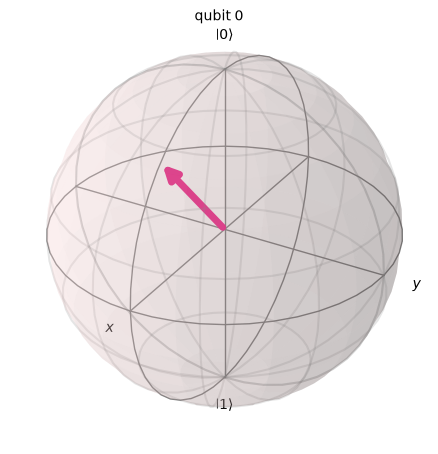

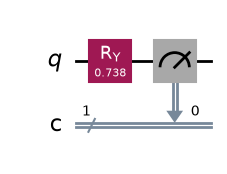

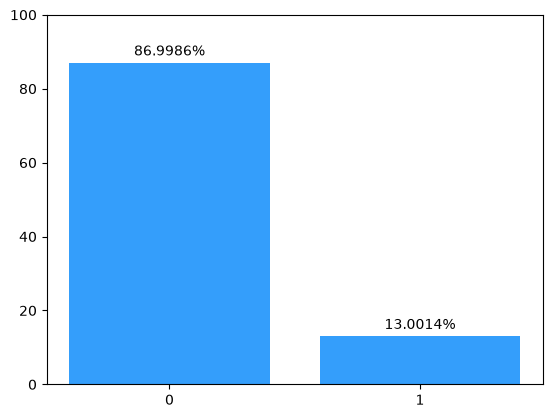

In [9]:
'''Il programma simula un circuito quantistico a singolo qubit in cui la probabilità di misurare lo stato '0' viene 
scelta dall'utente. Il codice calcola l'angolo di rotazione necessario per ottenere tale percentuale, simula un milione 
di misurazioni per raccogliere i dati statistici e infine mostra i risultati percentuali in un semplice grafico a barre.'''



import math
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import numpy as np
import matplotlib.pyplot as plt
from qiskit.visualization import plot_bloch_multivector
from qiskit.visualization import circuit_drawer
from qiskit.quantum_info import Statevector
from qiskit.visualization import (
    plot_bloch_multivector, 
    plot_state_qsphere, 
    plot_histogram
)


#Richiedo in input la probabilità che la misurazione del qubit sia 0
while True:
    prob = float(input("La probabilità percentuale di misurare il qubit nello stato 0 è: "))
    if 0 <= prob <= 100:
        break  
    
#Configurazione circuito
qc = QuantumCircuit(1,1)
angolo = math.acos((prob/50)-1)
qc.ry(theta=angolo, qubit = 0)

#Rappresentazione vettore su sfera di Bloch
stato = Statevector(qc)
fig = plot_bloch_multivector(stato)
display(fig)

#Misurazione qubit
qc.measure(0,0)

#Rappresentazione Grafica Circuito
c = qc.draw('mpl')
display(c)

#Creo ambiente di simulazione
simulator = AerSimulator()

#Avvio il circuito per 1000000 volte
job = simulator.run(qc, shots= 1000000)

#Organizzo i risultati e calcolo la percentuale di 0 e 1 misurati
result= job.result()
counts = result.get_counts()
n_0 = counts.get('0', 0)/10000
n_1 = counts.get('1', 0)/10000
stati = ['0', '1']
percentuali = [n_0, n_1]

#Creo istogramma con i risultati ottenuti
plt.bar(stati, percentuali, color="#349EFB")
plt.ylim(0, 100)
for i, v in enumerate(percentuali): #La funzione enumerate restituisce il valore della percentuale "v" associato alla indice corrispondente "i"
    plt.text(i, v + 2, f"{v}%", ha='center')
plt.show()




